# 05 · Experiment with learned masks for rough middle drawings

Add two learned masks that control how much of each motion-shifted drawing reaches the U-Net. Continue from the epoch-10 parent with ink weight 15 and compare with the unmasked model. The configured total target is epoch 15.

**Setup:** Kaggle with a GPU, Stage 1 data, and the epoch-10 Stage 2 checkpoint. Set `RESUME_INPUT` to continue an existing masking run.

**Saves:** Masked-model checkpoints, validation scores, comparison plots, mask previews, and downloadable ZIPs.

In [13]:
from pathlib import Path

EPOCHS = 15
COPY_STAGE2_TO_WORKING = True  # Copy the epoch-10 parent on a fresh run.
DATASETS = Path("/kaggle/input/datasets/epicfaez")
STAGE1_INPUT = DATASETS / "interframes-stage1-output" / "interframes_tf_stage1"
PARENT_INPUT = DATASETS / "interframes-stage2-output" / "interframes_tf_stage2"
RESUME_INPUT = None  # Optional attached masking ZIP, extracted folder, or saved notebook output root.
CONTROL_INPUT = (
    DATASETS / "interframes-stage2-ink15" / "interframes_tf_stage2_ink15"
)  # Attach the unmasked ink-15 ZIP/folder here for saved epochs and matched previews.

WORK_ROOT = Path("/kaggle/working")
TEMP_ROOT = Path("/kaggle/temp/interframes_masking")
OUT = WORK_ROOT / "interframes_tf_stage4_masking"
BACKUP_ZIP = WORK_ROOT / "interframes_stage4_masking_backup.zip"
CHECKPOINT_DIR = WORK_ROOT / "masking_checkpoints"
RESULTS_DIR = OUT / "results"
CHECKPOINT_EVERY_BATCHES = 1000
PREVIEW_CASES = 4
EXPERIMENT = "epoch10_two_warp_masks_ink15_v1"
LINE_THRESHOLD, LINE_TOLERANCE_PX = 0.5, 2

## Select the GPU

Use the available TensorFlow GPU and the batch size stored in the parent run.

In [14]:
import contextlib
import csv
import gc
import hashlib
import json
import math
import os
import shutil
import sqlite3
import sys
import time
import uuid
import warnings
import zipfile
from collections import defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache

os.environ["KERAS_BACKEND"] = "tensorflow"
TEMP_ROOT.mkdir(parents=True, exist_ok=True)
WORK_ROOT.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from IPython.display import display
from PIL import Image
from scipy.ndimage import distance_transform_edt
from tensorflow import keras
from tqdm.auto import tqdm

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
tf.config.experimental.enable_tensor_float_32_execution(False)
ENVIRONMENT = "kaggle_gpu" if gpus else "kaggle_cpu"
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "|", ENVIRONMENT)
if gpus:
    print(
        tf.config.experimental.get_device_details(gpus[0]).get(
            "device_name", gpus[0].name
        )
    )
else:
    print(
        "CPU runtime. Enable a GPU in Kaggle notebook settings for a full training run."
    )
if EPOCHS < 10 or CHECKPOINT_EVERY_BATCHES < 1:
    raise ValueError("Use EPOCHS >= 10 and a positive checkpoint interval.")

TensorFlow 2.21.0 | Keras 3.13.2 | kaggle_gpu
Tesla T4


## Open Stage 1

Read the attached frames and RAFT motion files. Extract ZIP inputs once under `/kaggle/temp`.

In [15]:
def read_json_file(path):
    return json.loads(Path(path).read_text())


def marker_in_zip(archive, filename):
    matches = [
        n
        for n in archive.namelist()
        if Path(n).name == filename and "_checkpoints" not in Path(n).parts
    ]
    if len(matches) != 1:
        raise ValueError(
            f"ZIP must contain one top-level {filename}; found {matches[:5]}"
        )
    return matches[0]


def safe_extract(archive, destination):
    destination = Path(destination).resolve()
    for info in archive.infolist():
        p = Path(info.filename)
        target = (destination / p).resolve()
        if p.is_absolute() or ".." in p.parts or not target.is_relative_to(destination):
            raise ValueError(f"Unsafe archive path: {info.filename}")
        if (info.external_attr >> 16) & 0o170000 == 0o120000:
            raise ValueError("Symlinks are not accepted in checkpoint/data ZIPs.")
    for info in tqdm(archive.infolist(), desc="Extracting locally", unit="entry"):
        archive.extract(info, destination)


def unpack_bundle(source, cache, marker):
    source, cache = Path(source), Path(cache)
    with zipfile.ZipFile(source) as archive:
        member = marker_in_zip(archive, marker)
        signature = hashlib.sha256(
            "\n".join(
                f"{i.filename}:{i.CRC}:{i.file_size}" for i in archive.infolist()
            ).encode()
        ).hexdigest()
        ready = cache / "extraction_complete.json"
        if not ready.is_file() or read_json_file(ready).get("signature") != signature:
            temporary = cache.with_name(cache.name + ".extracting")
            if temporary.exists():
                shutil.rmtree(temporary)
            temporary.mkdir(parents=True)
            print(
                "Extracting ALL ZIP contents to local runtime storage:",
                source,
                flush=True,
            )
            safe_extract(archive, temporary)
            (temporary / "extraction_complete.json").write_text(
                json.dumps(dict(signature=signature))
            )
            if cache.exists():
                shutil.rmtree(cache)
            temporary.replace(cache)
        return cache / Path(member).parent


def input_path(path):
    # Kaggle also exposes some attached datasets under /kaggle/input/<slug>.
    path = Path(path)
    legacy = (
        Path("/kaggle/input") / path.relative_to(DATASETS)
        if path.is_relative_to(DATASETS)
        else path
    )
    return legacy if not path.exists() and legacy.exists() else path


def stage_input(source, label, marker_name):
    """Publish a complete working copy only after every input file has been copied."""
    source = Path(source)
    if not COPY_STAGE2_TO_WORKING:
        return source
    cache = WORK_ROOT / "interframes_inputs"
    cache.mkdir(exist_ok=True)
    dest = cache / label
    status = cache / f"{label}.json"
    if source.is_dir():
        marker = source / marker_name
        if not marker.is_file():
            raise FileNotFoundError(
                f"Expected {marker}. Check the input path in the first cell."
            )
        signature = hashlib.sha256(marker.read_bytes()).hexdigest()
    else:
        with zipfile.ZipFile(source) as archive:
            signature = hashlib.sha256(
                archive.read(marker_in_zip(archive, marker_name))
            ).hexdigest()
    identity = dict(source=str(source.resolve()), marker=signature)
    if (
        status.is_file()
        and dest.is_dir()
        and read_json_file(status) == identity
        and (dest / marker_name).is_file()
    ):
        print("Reusing working copy:", dest, flush=True)
        return dest
    scratch = cache / (label + ".copying")
    if scratch.exists():
        shutil.rmtree(scratch)
    scratch.mkdir()
    if source.is_file():
        with zipfile.ZipFile(source) as archive:
            member = marker_in_zip(archive, marker_name)
            safe_extract(archive, scratch)
        copied_root = scratch / Path(member).parent
    else:
        print("Copying Kaggle input:", source, flush=True)
        with tqdm(desc=f"Copy {label}", unit="file") as bar:

            def copy_with_progress(src, dst):
                shutil.copyfile(src, dst)
                bar.update(1)
                return dst

            shutil.copytree(
                source, scratch, dirs_exist_ok=True, copy_function=copy_with_progress
            )
        copied_root = scratch
    if (
        hashlib.sha256((copied_root / marker_name).read_bytes()).hexdigest()
        != signature
    ):
        raise ValueError(f"Input changed while copying {label}. Rerun this cell.")
    # Invalidate the old receipt before publishing its replacement.
    status.unlink(missing_ok=True)
    if dest.exists():
        shutil.rmtree(dest)
    copied_root.replace(dest)
    if scratch.exists():
        shutil.rmtree(scratch)
    receipt = status.with_suffix(".part")
    receipt.write_text(json.dumps(identity))
    receipt.replace(status)
    print("Working copy ready:", dest, flush=True)
    return dest


STAGE1_INPUT = input_path(STAGE1_INPUT)
PARENT_INPUT = input_path(PARENT_INPUT)
if STAGE1_INPUT.is_file():
    DATA_ROOT = unpack_bundle(
        STAGE1_INPUT, TEMP_ROOT / "stage1", "stage1_complete.json"
    )
else:
    DATA_ROOT = STAGE1_INPUT
marker = DATA_ROOT / "stage1_complete.json"
if not marker.is_file():
    raise FileNotFoundError(f"Stage 1 completion marker missing: {marker}")
meta = read_json_file(marker)
print("Stage 1:", DATA_ROOT, "| triplets:", meta["triplets"])

Stage 1: /kaggle/input/datasets/epicfaez/interframes-stage1-output/interframes_tf_stage1 | triplets: {'test': 53290, 'train': 58390, 'val': 29188}


## Check the dataset

Check that the dataset identifier, start/middle/end examples, and motion-file indices agree for training and validation.

In [16]:
from pathlib import Path

module_dir = DATA_ROOT / "modules"
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))
for name in ("data", "learning"):
    loaded = sys.modules.get(name)
    if (
        loaded
        and Path(getattr(loaded, "__file__", "")).resolve()
        != (module_dir / f"{name}.py").resolve()
    ):
        raise RuntimeError(
            f"Restart the runtime to load {name} from the selected Stage 1 archive."
        )
import data as raster
import learning

fingerprint, _ = raster.bundle_fingerprint(DATA_ROOT)
if fingerprint != meta["fingerprint"]:
    raise ValueError("Stage 1 contents differ from its completion marker.")
data_size = int(read_json_file(DATA_ROOT / "config.json")["size"])
manifest = raster.read_records(DATA_ROOT)
splits = {
    split: [r for r in manifest if r["split"] == split] for split in ("train", "val")
}
del manifest
for split, rows in splits.items():
    n = int(meta["triplets"][split])
    done = np.load(
        DATA_ROOT / "flows" / f"{split}_done.npy", mmap_mode="r", allow_pickle=False
    )
    flow = raster.open_flows(DATA_ROOT, split)
    if (
        not n
        or len(rows) != n
        or len(done) != n
        or not done.all()
        or flow.shape != (n, 2, data_size // 8, data_size // 8, 2)
        or sorted(int(r["cache_index"]) for r in rows) != list(range(n))
    ):
        raise ValueError(f"Manifest and completed motion cache disagree for {split}.")
    print(f"Full {split} split: {n:,} triplets.")

Full train split: 58,390 triplets.
Full val split: 29,188 triplets.


## Build batches

Keep drawings and distance-to-line maps in memory. Use saved motion in both directions to shift the endpoint ink toward the middle.

In [17]:
class FastFrames:
    def __init__(self, root, size, ram_gib=8):
        self.root, self.size = Path(root), int(size)
        self.flows = {}
        # Per-entry storage: uint8 image + float32 distance map, plus modest LRU overhead.
        capacity = max(1, int(ram_gib * 1024**3 / (size * size * 5 + 512)))
        self.gray = lru_cache(maxsize=capacity)(self._gray)
        self.distance = lru_cache(maxsize=capacity)(self._distance)
        self.gy, self.gx = np.mgrid[:size, :size].astype(np.float32)

    def _gray(self, relative):
        with Image.open(self.root / relative) as im:
            result = np.asarray(im.convert("L"), dtype=np.uint8).copy()
        if result.shape != (self.size, self.size):
            raise ValueError(f"Unexpected frame size: {relative}: {result.shape}")
        result.setflags(write=False)
        return result

    def ink(self, relative):
        return 1.0 - self.gray(relative).astype(np.float32) / 255.0

    def _distance(self, relative):
        result = raster.distance_map(self.ink(relative))
        result.setflags(write=False)
        return result

    def load_flow(self, split):
        if split not in self.flows:
            print(
                f"Loading existing {split} motion cache into RAM (no RAFT recomputation)...",
                flush=True,
            )
            self.flows[split] = np.array(raster.open_flows(self.root, split), copy=True)

    def splat(self, ink, flow):
        dxpos = self.gx + 0.5 * flow[..., 0]
        dypos = self.gy + 0.5 * flow[..., 1]
        x0, y0 = np.floor(dxpos).astype(np.int64), np.floor(dypos).astype(np.int64)
        dx, dy = dxpos - x0, dypos - y0
        accum = np.zeros(self.size * self.size, np.float32)
        norm = np.zeros_like(accum)
        for ox, oy, weight in [
            (0, 0, (1 - dx) * (1 - dy)),
            (1, 0, dx * (1 - dy)),
            (0, 1, (1 - dx) * dy),
            (1, 1, dx * dy),
        ]:
            x, y = x0 + ox, y0 + oy
            valid = (
                (x >= 0) & (x < self.size) & (y >= 0) & (y < self.size) & (weight > 0)
            )
            indices = y[valid] * self.size + x[valid]
            accum += np.bincount(
                indices, weights=(weight * ink)[valid], minlength=accum.size
            ).astype(np.float32)
            norm += np.bincount(
                indices, weights=weight[valid], minlength=norm.size
            ).astype(np.float32)
        valid = norm > 1e-6
        warped = np.divide(accum, norm, out=np.zeros_like(accum), where=valid)
        return warped.reshape(ink.shape), valid.reshape(ink.shape).astype(np.float32)

    def batch(self, rows):
        x = np.empty((len(rows), self.size, self.size, 8), np.float32)
        y = np.empty((len(rows), self.size, self.size, 1), np.float32)
        for i, row in enumerate(rows):
            a, b = self.ink(row["a"]), self.ink(row["b"])
            flow = self.flows[row["split"]][row["cache_index"]]
            wa, va = self.splat(a, raster.upsample_low(flow[0], self.size))
            wb, vb = self.splat(b, raster.upsample_low(flow[1], self.size))
            x[i] = np.stack(
                [
                    a,
                    b,
                    wa,
                    wb,
                    self.distance(row["a"]),
                    self.distance(row["b"]),
                    va,
                    vb,
                ],
                axis=-1,
            )
            y[i, ..., 0] = self.ink(row["target"])
        return x, y


def batches(frames, rows, batch_size, start=0, workers=2):
    """Bounded threaded prefetch; yields deterministic ordered batches."""
    total = math.ceil(len(rows) / batch_size)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        queue = deque()
        next_index = start
        while next_index < total or queue:
            while next_index < total and len(queue) < max(1, workers):
                chosen = rows[next_index * batch_size : (next_index + 1) * batch_size]
                queue.append((next_index, chosen, pool.submit(frames.batch, chosen)))
                next_index += 1
            index, chosen, future = queue.popleft()
            x, y = future.result()
            yield index, chosen, x, y

## Check the fast loader

Set the image cache size and verify that the faster loader produces the same eight inputs as the original Stage 1 code.

In [18]:
try:
    import psutil

    available = psutil.virtual_memory().available
except ImportError:
    available = 6 * 1024**3
try:
    limit = Path("/sys/fs/cgroup/memory.max").read_text().strip()
    if limit.isdigit():
        headroom = int(limit) - int(Path("/sys/fs/cgroup/memory.current").read_text())
        if headroom > 0:
            available = min(available, headroom)
except OSError:
    pass
IMAGE_CACHE_GIB = max(0.25, min(8.0, available * 0.28 / 1024**3))
CPU_WORKERS = max(1, min(4, (os.cpu_count() or 2) // 2))
frame_cache = FastFrames(DATA_ROOT, data_size, IMAGE_CACHE_GIB)
for split in ("train", "val"):
    frame_cache.load_flow(split)
sample = splits["train"][:2]
fast_x, _ = frame_cache.batch(sample)
for index, row in enumerate(sample):
    original = raster.row_features(DATA_ROOT, row, frame_cache.flows["train"])
    np.testing.assert_allclose(fast_x[index], original, rtol=1e-5, atol=2e-6)
print(
    f"Feature parity passed | image cache {IMAGE_CACHE_GIB:.1f} GiB | {CPU_WORKERS} preprocessing workers."
)

Loading existing train motion cache into RAM (no RAFT recomputation)...
Loading existing val motion cache into RAM (no RAFT recomputation)...
Feature parity passed | image cache 7.0 GiB | 2 preprocessing workers.


## Check saved training files

Verify that the model, optimizer, and progress files belong to the same completed save before restoring them.

In [22]:
def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".part")
    with temp.open("w") as f:
        json.dump(value, f, indent=2, allow_nan=False)
        f.flush()
        os.fsync(f.fileno())
    os.replace(temp, path)


def atomic_copy(source, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temp = destination.with_name(destination.name + ".part")
    shutil.copyfile(source, temp)
    os.replace(temp, destination)


def weights_digest(model):
    h = hashlib.sha256()
    for v in model.weights:
        a = np.asarray(v.numpy())
        h.update(str(a.shape).encode())
        h.update(str(a.dtype).encode())
        h.update(a.tobytes())
    return h.hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text())


def state_rank(state):
    p = state.get("partial") or {}
    return (
        int(state["completed_epochs"]),
        int(p.get("samples", 0)),
        int(state.get("optimizer_iterations", 0)),
    )


def checkpoint_source(folder):
    """Only committed generations are eligible once this runtime has saved one."""
    folder = Path(folder)
    generations = []
    for marker in (folder / "_checkpoints").glob("*/COMMITTED.json"):
        try:
            meta = read_json(marker)
            state = read_json(marker.parent / "training_state.json")
            generations.append(
                (state_rank(state), marker.parent.name, marker.parent, meta)
            )
        except (ValueError, OSError, KeyError):
            continue
    for _, _, directory, meta in sorted(generations, reverse=True):
        if all(
            (directory / n).is_file() and raster.digest(directory / n) == sha
            for n, sha in meta["sha256"].items()
        ):
            return directory
        print("Ignoring incomplete/damaged checkpoint:", directory.name, flush=True)
    if generations:
        raise RuntimeError(
            "No intact committed checkpoint. Restore the latest verified backup ZIP."
        )
    required = ["training_state.json", "last.keras", "best.keras"]
    if all((folder / n).is_file() for n in required):
        if (folder / "checkpoint_integrity.json").is_file():
            meta = read_json(folder / "checkpoint_integrity.json")
            if not all(
                (folder / n).is_file() and raster.digest(folder / n) == sha
                for n, sha in meta["sha256"].items()
            ):
                raise RuntimeError(
                    "Checkpoint integrity check failed. Restore the latest verified backup ZIP."
                )
        return folder
    raise FileNotFoundError(f"No resumable checkpoint in {folder}")

## Select the checkpoint

Resume a checked masking run, or copy the completed epoch-10 parent and load its `last.keras`.

In [23]:
def bundle_member(relative):
    relative = Path(relative)
    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError("Unexpected path in checkpoint metadata.")
    return relative


class Bundle:
    """Read a Stage 2/4 ZIP or a prepared checkpoint folder through the same interface."""

    def __init__(self, source):
        self.source = Path(source)

    def __enter__(self):
        self.archive = None
        if self.source.is_dir():
            self.root = self.source
        else:
            self.archive = zipfile.ZipFile(self.source)
            try:
                self.root = Path(
                    marker_in_zip(self.archive, "training_state.json")
                ).parent
            except Exception:
                self.archive.close()
                raise
        return self

    def __exit__(self, *args):
        if self.archive is not None:
            self.archive.close()

    def open(self, relative):
        name = self.root / bundle_member(relative)
        return self.archive.open(name.as_posix()) if self.archive else name.open("rb")

    def has(self, relative):
        name = self.root / bundle_member(relative)
        return (
            name.as_posix() in self.archive.NameToInfo
            if self.archive
            else name.is_file()
        )

    def json(self, relative):
        with self.open(relative) as f:
            return json.load(f)

    def copy(self, relative, dest):
        temp = dest.with_name(dest.name + ".part")
        with self.open(relative) as src, temp.open("wb") as out:
            shutil.copyfileobj(src, out, 8 * 1024**2)
        temp.replace(dest)


def checkpoint_inputs(path):
    if path is None:
        return []
    path = Path(path)
    if path.is_file() or (path / "training_state.json").is_file():
        return [path]
    if not path.is_dir():
        return []
    return sorted(
        [*path.glob("checkpoint_*.zip"), *path.glob("epoch_*.zip")],
        key=lambda p: p.stat().st_mtime_ns,
        reverse=True,
    )


def is_branch(state):
    cfg = state.get("run_config", {})
    return (
        state.get("experiment") == EXPERIMENT
        and state.get("parent_epoch") == 10
        and cfg.get("data_fingerprint") == meta["fingerprint"]
        and cfg.get("positive_weight") == 15
        and bool(state.get("parent_weights_digest"))
    )


def masked_source():
    choices = []
    damaged = False
    if (OUT / "training_state.json").exists() or any(
        (OUT / "_checkpoints").glob("*/COMMITTED.json")
    ):
        try:
            source = checkpoint_source(OUT)
            state = read_json(source / "training_state.json")
            if not is_branch(state):
                raise ValueError(
                    "Local output belongs to a different experiment or dataset."
                )
            choices.append((state_rank(state), 1, 0, source))
        except (OSError, ValueError, KeyError, RuntimeError) as error:
            print("Local checkpoint:", error, flush=True)
            damaged = True
    attached = []
    if RESUME_INPUT is not None:
        path = Path(RESUME_INPUT)
        if (path / BACKUP_ZIP.name).is_file():
            path = path / BACKUP_ZIP.name
        elif (path / OUT.name / "training_state.json").is_file():
            path = path / OUT.name
        elif (path / CHECKPOINT_DIR.name).is_dir():
            path = path / CHECKPOINT_DIR.name
        attached = checkpoint_inputs(path)
        if not attached:
            raise FileNotFoundError(f"No masking checkpoint at RESUME_INPUT: {path}")
    for item in dict.fromkeys(
        attached
        + checkpoint_inputs(CHECKPOINT_DIR)
        + ([BACKUP_ZIP] if BACKUP_ZIP.is_file() else [])
    ):
        try:
            with Bundle(item) as bundle:
                state = bundle.json("training_state.json")
            if not is_branch(state):
                raise ValueError(
                    "Incorrect experiment or dataset in the masking backup directory."
                )
            choices.append((state_rank(state), 0, item.stat().st_mtime_ns, item))
        except (
            OSError,
            KeyError,
            ValueError,
            RuntimeError,
            zipfile.BadZipFile,
        ) as error:
            print("Skipping unreadable checkpoint:", item.name, error, flush=True)
            damaged = True
    for rank, local, _, item in sorted(choices, reverse=True):
        if local:
            print("Using committed local masking checkpoint:", rank, flush=True)
            return item
        try:
            restored = (
                item
                if item.is_dir()
                else unpack_bundle(item, TEMP_ROOT / "restore", "training_state.json")
            )
            checkpoint_source(restored)  # Verify hashes before replacing local state.
        except (
            OSError,
            KeyError,
            ValueError,
            RuntimeError,
            zipfile.BadZipFile,
        ) as error:
            print("Trying previous backup:", item.name, error, flush=True)
            damaged = True
            continue
        incoming = WORK_ROOT / "_interframes_masking_incoming"
        if incoming.exists():
            shutil.rmtree(incoming)
        shutil.copytree(restored, incoming)
        if OUT.exists():
            shutil.move(str(OUT), str(TEMP_ROOT / f"replaced_{time.time_ns()}"))
        incoming.replace(OUT)
        print(
            "Restored verified masking backup from backup:",
            item.name,
            "| progress",
            rank,
            flush=True,
        )
        return checkpoint_source(OUT)
    if damaged:
        raise RuntimeError(
            "No intact matching branch checkpoint found. Keep the masking backups and check the configured folder."
        )
    return None


def load_parent():
    paths = checkpoint_inputs(PARENT_INPUT)
    if not paths:
        raise FileNotFoundError(
            f"Point PARENT_INPUT at the original epoch-10 ZIP or folder: {PARENT_INPUT}"
        )
    for item in paths:
        with Bundle(item) as bundle:
            state = bundle.json("training_state.json")
            cfg = state["run_config"]
            if not (
                int(state["completed_epochs"]) == 10
                and not state.get("partial")
                and cfg.get("positive_weight") == 30
                and cfg["data_fingerprint"] == meta["fingerprint"]
                and not state.get("experiment")
            ):
                continue
        staged = stage_input(item, "interframes_tf_stage2", "training_state.json")
        with Bundle(staged) as bundle:
            if staged.is_dir():
                dest = staged / "last.keras"
            else:
                dest = TEMP_ROOT / "interframes_masking_parent_epoch10.keras"
                bundle.copy("last.keras", dest)
            if bundle.has("checkpoint_integrity.json"):
                sha = bundle.json("checkpoint_integrity.json")["sha256"]["last.keras"]
                if raster.digest(dest) != sha:
                    raise ValueError(f"Parent model checksum failed in {item}.")
        parent = load_network(dest)
        if int(parent.optimizer.iterations.numpy()) != int(
            state["optimizer_iterations"]
        ):
            raise ValueError(
                "Parent model and training state have different Adam step counts."
            )
        print("Starting from", item, "| original last.keras, epoch 10.", flush=True)
        return parent, state
    raise ValueError(
        "PARENT_INPUT must contain an unmasked, completed epoch 10, ink weight 30, matching Stage 1."
    )

## Add two trainable masks

Each mask scales one rough middle drawing before it enters the U-Net. The masks start about 98.2% open. Both masks and the U-Net learn from the true middle drawing.

In [24]:
def saved_policy(path):
    with zipfile.ZipFile(path) as archive:
        layers = json.loads(archive.read("config.json"))["config"]["layers"]
    for layer in layers:
        if layer["config"].get("name") == "interframes_unet":
            layers = layer["config"]["layers"]
            break
    conv = next(
        layer for layer in layers if layer["config"].get("name") == "enc0_conv1"
    )
    dtype = conv["config"]["dtype"]
    return dtype["config"]["name"] if isinstance(dtype, dict) else dtype


def load_network(path, training=True):
    keras.mixed_precision.set_global_policy(saved_policy(path))
    with warnings.catch_warnings(record=True) as notices:
        warnings.simplefilter("always")
        model = keras.models.load_model(path, compile=training)
    for notice in notices:
        if training and "Skipping variable loading for optimizer" in str(
            notice.message
        ):
            raise ValueError(f"Optimizer did not restore completely: {notice.message}")
    return model


def optimizer_state(optimizer):
    # Wrapper and inner Adam both have an iteration counter and learning-rate variable.
    inner = getattr(optimizer, "inner_optimizer", optimizer)
    inner_ids = {id(v) for v in inner.variables}
    keyed = {
        (("adam" if id(v) in inner_ids else "wrapper"), v.name): v
        for v in optimizer.variables
    }
    if len(keyed) != len(optimizer.variables):
        raise ValueError("Optimizer variable names are ambiguous.")
    return keyed


def attach_masks(parent):
    if (
        parent.name != "interframes_unet"
        or getattr(parent.loss, "positive_weight", None) != 30
    ):
        raise ValueError(
            "The parent must be the original full U-Net with ink weight 30."
        )
    # The outer model owns the optimizer. Restore just the backbone architecture here.
    backbone = keras.Model.from_config(parent.get_config())
    backbone.set_weights(parent.get_weights())
    if weights_digest(parent) != weights_digest(backbone):
        raise ValueError("U-Net weights changed while building the masking branch.")
    features = keras.Input(
        shape=parent.input_shape[1:], dtype="float32", name="frame_features"
    )
    hidden = keras.layers.Conv2D(
        8, 3, padding="same", activation="relu", dtype="float32", name="mask_context"
    )(features)
    gates = keras.layers.Conv2D(
        2,
        1,
        activation="sigmoid",
        dtype="float32",
        kernel_initializer="zeros",
        bias_initializer=keras.initializers.Constant(4.0),
        name="warp_visibility",
    )(hidden)
    ab, warps, distance_and_coverage = keras.ops.split(features, [2, 4], axis=-1)
    visible_warps = keras.layers.Multiply(dtype="float32", name="gated_warps")(
        [warps, gates]
    )
    merged = keras.layers.Concatenate(dtype="float32", name="masked_features")(
        [ab, visible_warps, distance_and_coverage]
    )
    model = keras.Model(features, backbone(merged), name="interframes_masked_unet")

    optimizer = keras.optimizers.deserialize(
        keras.optimizers.serialize(parent.optimizer)
    )
    model.compile(
        optimizer=optimizer,
        loss=learning.InkLoss(positive_weight=15),
        metrics=[learning.ink_mae],
        jit_compile=False,
        auto_scale_loss=False,
    )
    optimizer.build(model.trainable_variables)
    source, destination = optimizer_state(parent.optimizer), optimizer_state(optimizer)
    for key, value in source.items():
        if key not in destination or destination[key].shape != value.shape:
            raise ValueError(f"Cannot transfer Adam state for {key}.")
        destination[key].assign(value)
        np.testing.assert_array_equal(destination[key].numpy(), value.numpy())
    new_keys = destination.keys() - source.keys()
    if not new_keys or any(
        not key[1].startswith(("mask_context_", "warp_visibility_")) for key in new_keys
    ):
        raise ValueError("Unexpected new optimizer state outside the two mask layers.")
    for key in new_keys:
        np.testing.assert_array_equal(
            destination[key].numpy(), np.zeros(destination[key].shape)
        )
    print(
        f"Preserved {len(source)} optimizer variables. New mask slots: {len(new_keys)}.",
        flush=True,
    )
    return model

## Define checkpoint backups

Save a checked ZIP after each completed epoch and rolling backups during training and validation. Download the ZIP or save Kaggle outputs to keep progress across sessions.

In [25]:
class CheckpointFiles:
    def backup(self):
        """One atomic, CRC-verified ZIP; a previous verified ZIP survives interruption."""
        self.backup_path.parent.mkdir(parents=True, exist_ok=True)
        temp = self.backup_path.with_name(self.backup_path.name + ".part")
        excluded = {"_checkpoints", "__pycache__", ".ipynb_checkpoints"}
        members = [
            p
            for p in self.out.rglob("*")
            if p.is_file()
            and not excluded.intersection(p.relative_to(self.out).parts)
            and p.suffix not in {".part", ".tmp"}
            and not p.name.endswith(("-journal", "-shm", "-wal"))
            and not p.name.endswith(".tmp.keras")
        ]
        print("Creating disk backup ZIP...", flush=True)
        with zipfile.ZipFile(temp, "w", zipfile.ZIP_STORED, allowZip64=True) as z:
            for p in members:
                z.write(p, Path(self.out.name) / p.relative_to(self.out))
        with zipfile.ZipFile(temp) as z:
            bad = z.testzip()
            if bad:
                raise IOError(f"Backup CRC failed: {bad}")
        with temp.open("rb") as f:
            os.fsync(f.fileno())
        os.replace(temp, self.backup_path)
        print(
            f"Backup verified: {self.backup_path} ({self.backup_path.stat().st_size / 1024**2:.1f} MiB)",
            flush=True,
        )
        if self.durable_backup_dir:
            self.persist_backup()

    def persist_backup(self):
        directory = self.durable_backup_dir
        directory.mkdir(parents=True, exist_ok=True)
        epoch = int(self.state["completed_epochs"])
        if epoch > 10 and not self.state.get("partial"):
            destination = directory / f"epoch_{epoch:03d}.zip"
        else:
            destination = directory / f"checkpoint_{time.time_ns()}.zip"
        temporary = destination.with_suffix(".zip.part")
        print("Saving a checkpoint under /kaggle/working...", flush=True)
        shutil.copyfile(self.backup_path, temporary)
        with zipfile.ZipFile(temporary) as z:
            if z.testzip() is not None:
                raise IOError(
                    "Checkpoint ZIP verification failed. the previous backup is retained."
                )
        os.replace(temporary, destination)
        atomic_json(
            directory / "latest.json",
            dict(
                file=destination.name,
                rank=state_rank(self.state),
                completed_epochs=self.state["completed_epochs"],
            ),
        )
        previous = sorted(directory.glob("checkpoint_*.zip"), reverse=True)
        for p in previous[2:]:
            p.unlink()
        print("Checkpoint ZIP verified:", destination, flush=True)

    def checkpoint(self, improved=False):
        """Save a model/state pair, publish only after its hashes are durable."""
        self.state["optimizer_iterations"] = int(
            self.model.optimizer.iterations.numpy()
        )
        self.state["run_config"] = self.config
        self.state["checkpoint_schema"] = "portable-v2"
        self.state["execution"] = dict(
            environment=self.environment,
            batch_size=self.batch_size,
            compute_policy=self.compute_policy,
        )
        root = self.out / "_checkpoints"
        root.mkdir(exist_ok=True)
        name = f"{int(self.state['optimizer_iterations']):012d}-{time.time_ns()}-{uuid.uuid4().hex[:6]}"
        staging = root / (name + ".pending")
        staging.mkdir()
        print("Saving model, optimizer and resume state...", flush=True)
        self.model.save(staging / "last.keras")
        if improved:
            shutil.copyfile(staging / "last.keras", staging / "best.keras")
        else:
            shutil.copyfile(self.best_path, staging / "best.keras")
        atomic_json(staging / "training_state.json", self.state)
        atomic_json(staging / "history.json", self.state["history"])
        atomic_json(staging / "run_config.json", self.config)
        hashes = {p.name: raster.digest(p) for p in staging.iterdir() if p.is_file()}
        # Flush payloads before the commit marker becomes visible.
        for p in staging.iterdir():
            with p.open("rb") as f:
                os.fsync(f.fileno())
        atomic_json(staging / "COMMITTED.json", {"sha256": hashes})
        committed = root / name
        os.replace(staging, committed)
        for filename in [
            "last.keras",
            "best.keras",
            "history.json",
            "run_config.json",
            "training_state.json",
        ]:
            atomic_copy(committed / filename, self.out / filename)
        atomic_json(self.out / "checkpoint_integrity.json", {"sha256": hashes})
        self.write_marker()
        self.backup()
        # Keep two complete generations; clean abandoned writes only after backup succeeds.
        generations = sorted(
            (
                p
                for p in root.iterdir()
                if p.is_dir() and (p / "COMMITTED.json").exists()
            ),
            key=lambda p: p.name,
            reverse=True,
        )
        for p in generations[2:]:
            shutil.rmtree(p)
        for p in root.glob("*.pending"):
            shutil.rmtree(p)

    def write_marker(self):
        atomic_json(
            self.out / "masking_state.json",
            {
                "data_fingerprint": self.meta["fingerprint"],
                "best_sha256": raster.digest(self.best_path),
                "completed_epochs": self.state["completed_epochs"],
                "best_epoch": self.state["best_epoch"],
                "best_val": self.state["best_val"],
                "partial_epoch": self.state.get("partial"),
                "scope": "full",
                "experiment": EXPERIMENT,
                "parent_weights_digest": self.state["parent_weights_digest"],
                "tensorflow": tf.__version__,
                "keras": keras.__version__,
            },
        )

## Define validation scores

Measure how closely predicted lines match the reference within two pixels. Precision measures correct predicted ink; recall measures recovered reference ink; F1 combines them. Also report average line distance (Chamfer), ink amount, average pixel error (MAE), and loss.

In [26]:
def score_lines(pred, target, threshold, tolerance):
    p, g = pred >= threshold, target >= threshold
    if p.any() and g.any():
        to_target = distance_transform_edt(~g)[p]
        to_prediction = distance_transform_edt(~p)[g]
        precision = float(np.mean(to_target <= tolerance))
        recall = float(np.mean(to_prediction <= tolerance))
        f1 = 2 * precision * recall / max(precision + recall, 1e-8)
        chamfer = (to_target.mean() + to_prediction.mean()) / 2
    else:
        precision = recall = f1 = float(p.any() == g.any())
        chamfer = 0 if f1 else math.hypot(*p.shape)
    return (
        precision,
        recall,
        f1,
        float(chamfer),
        float(np.abs(pred - target).mean()),
        float(p.mean()),
        float(g.mean()),
    )


QUALITY = (
    "precision",
    "recall",
    "line_f1",
    "chamfer_px",
    "mae",
    "ink_fraction",
    "target_ink_fraction",
)


def evaluate_epoch(run, epoch):
    rows = run.splits["val"]
    digest = weights_digest(run.model)
    folder = run.out / "evaluation" / f"epoch_{epoch:03d}_{digest[:16]}"
    folder.mkdir(parents=True, exist_ok=True)
    protocol = dict(
        data_fingerprint=run.meta["fingerprint"],
        weights_digest=digest,
        epoch=epoch,
        split="val",
        positive_weight=15,
        threshold=run.threshold,
        tolerance=run.tolerance,
        compute_policy=run.compute_policy,
        n_triplets=len(rows),
    )
    tag = folder / "protocol.json"
    if tag.exists() and read_json(tag) != protocol:
        raise ValueError(f"Validation protocol differs from saved results in {folder}.")
    atomic_json(tag, protocol)
    if (folder / "summary.json").is_file():
        summary = read_json(folder / "summary.json")
        if summary["protocol"] == protocol and (folder / "per_triplet.csv").is_file():
            print(f"Reusing all {len(rows):,} saved validation scores.")
            return summary, folder

    loss_fn = learning.InkLoss(positive_weight=15)

    @tf.function(reduce_retracing=True)
    def infer(x, y):
        logits = run.model(x, training=False)
        return tf.sigmoid(tf.cast(logits, tf.float32)), loss_fn.call(y, logits)

    with contextlib.closing(sqlite3.connect(folder / "scores.sqlite")) as db:
        # Commit whole batches; a restored ZIP can resume a partly scored validation split.
        db.execute("PRAGMA journal_mode=DELETE")
        db.execute(
            "CREATE TABLE IF NOT EXISTS scores (id TEXT PRIMARY KEY, sequence TEXT, gap INTEGER,"
            " loss REAL, precision REAL, recall REAL, line_f1 REAL, chamfer_px REAL, mae REAL,"
            " ink_fraction REAL, target_ink_fraction REAL)"
        )
        done = {key for (key,) in db.execute("SELECT id FROM scores")}
        ids = {row["id"] for row in rows}
        if len(ids) != len(rows) or not done <= ids:
            raise ValueError("Validation triplet IDs differ from the stored report.")
        pending = [row for row in rows if row["id"] not in done]
        print(
            f"Epoch {epoch} validation: {len(done):,}/{len(rows):,} saved, {len(pending):,} remaining.",
            flush=True,
        )
        with (
            ThreadPoolExecutor(max_workers=run.workers) as pool,
            tqdm(
                total=len(rows),
                initial=len(done),
                desc="Full validation",
                unit="triplet",
            ) as progress,
        ):
            for index, chosen, x, y in batches(
                run.frames, pending, run.batch_size, workers=run.workers
            ):
                pred, losses = infer(x, y)
                pred, losses = pred.numpy()[..., 0], losses.numpy().reshape(-1)
                if not np.isfinite(pred).all() or not np.isfinite(losses).all():
                    raise FloatingPointError(
                        "Non-finite validation prediction or loss."
                    )
                jobs = [
                    pool.submit(score_lines, p, t[..., 0], run.threshold, run.tolerance)
                    for p, t in zip(pred, y)
                ]
                values = [
                    (r["id"], r["sequence"], int(r["gap"]), float(loss), *job.result())
                    for r, loss, job in zip(chosen, losses, jobs)
                ]
                with db:
                    db.executemany(
                        "INSERT INTO scores VALUES (?,?,?,?,?,?,?,?,?,?,?)", values
                    )
                progress.update(len(chosen))
                if (index + 1) % run.checkpoint_batches == 0:
                    run.backup()
        if db.execute("SELECT COUNT(*) FROM scores").fetchone()[0] != len(rows):
            raise ValueError("Validation is incomplete.")
        # This matches notebook 03: equal weight per sequence for line scores, per image for loss/MAE.
        averages = ", ".join(f"AVG({key})" for key in QUALITY)
        by_sequence = np.array(
            db.execute(f"SELECT {averages} FROM scores GROUP BY sequence").fetchall()
        )
        metrics = dict(zip(QUALITY, map(float, by_sequence.mean(axis=0))))
        loss, mae = db.execute("SELECT AVG(loss), AVG(mae) FROM scores").fetchone()
        summary = dict(protocol=protocol, loss=loss, ink_mae=mae, **metrics)
        target_fraction = metrics["target_ink_fraction"]
        summary["ink_ratio"] = (
            metrics["ink_fraction"] / target_fraction if target_fraction else None
        )
        results = db.execute("SELECT * FROM scores ORDER BY sequence, id")
        dest = folder / "per_triplet.csv"
        temp = dest.with_suffix(".csv.part")
        with temp.open("w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([c[0] for c in results.description])
            writer.writerows(results)
        temp.replace(dest)
    atomic_json(folder / "summary.json", summary)
    return summary, folder

## Define the resumable masking run

Restore the saved Adam training state and learning rate. Keep the parent batch size and repeatable shuffle order, and resume from the last checked batch.

In [27]:
class MaskingRun(CheckpointFiles):
    def __init__(self):
        source = masked_source()
        self.out, self.root = OUT, DATA_ROOT
        self.backup_path, self.durable_backup_dir = BACKUP_ZIP, CHECKPOINT_DIR
        self.meta, self.environment = meta, ENVIRONMENT
        self.checkpoint_batches = CHECKPOINT_EVERY_BATCHES
        self.threshold, self.tolerance = LINE_THRESHOLD, LINE_TOLERANCE_PX
        self.workers = CPU_WORKERS
        self.out.mkdir(parents=True, exist_ok=True)
        self.best_path = self.out / "best.keras"
        if source is None:
            parent, self.state = load_parent()
            keras.utils.set_random_seed(int(self.state["run_config"].get("seed", 42)))
            parent_digest = weights_digest(parent)
            self.model = attach_masks(parent)
            self.state["run_config"] = dict(
                self.state["run_config"], positive_weight=15
            )
            self.state.update(
                experiment=EXPERIMENT,
                parent_epoch=10,
                parent_weights_digest=parent_digest,
                partial=None,
                best_epoch=10,
                best_val=None,
                bad_epochs=0,
                best_weights_digest=weights_digest(self.model),
            )
            del parent
        else:
            self.state = read_json(source / "training_state.json")
            self.model = load_network(source / "last.keras")
            if (
                self.model.name != "interframes_masked_unet"
                or self.model.loss.positive_weight != 15
            ):
                raise ValueError("Invalid masking model or loss in this checkpoint.")
            if source != self.out:
                for name in (
                    "last.keras",
                    "best.keras",
                    "run_config.json",
                    "training_state.json",
                    "history.json",
                ):
                    if (source / name).is_file():
                        atomic_copy(source / name, self.out / name)
                if (source / "COMMITTED.json").is_file():
                    atomic_copy(
                        source / "COMMITTED.json",
                        self.out / "checkpoint_integrity.json",
                    )
        self.config = self.state["run_config"]
        self.seed = int(self.config["seed"])
        self.patience = int(self.config["patience"])
        self.batch_size = int(self.config["batch_size"])
        self.compute_policy = (
            self.model.get_layer("interframes_unet")
            .get_layer("enc0_conv1")
            .dtype_policy.name
        )
        if (
            int(self.model.optimizer.iterations.numpy())
            != self.state["optimizer_iterations"]
        ):
            raise ValueError("Restored model/sidecar optimizer iterations differ.")
        if (
            self.config["feature_version"] != learning.FEATURE_VERSION
            or self.config["size"] != data_size
        ):
            raise ValueError(
                "Stage 1 feature format or image size differs from the parent."
            )
        if tuple(self.model.input_shape[1:]) != (data_size, data_size, 8):
            raise ValueError("The model expects a different input shape.")
        self.splits, self.frames = splits, frame_cache
        if source is None:
            shutil.copytree(
                DATA_ROOT / "modules",
                self.out / "source_modules",
                dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("__pycache__"),
            )
            for name in ("config.json", "stage1_complete.json", "split_audit.json"):
                atomic_copy(DATA_ROOT / name, self.out / "source_data_metadata" / name)
            sample, _ = self.frames.batch(self.splits["train"][:1])
            gates = keras.Model(
                self.model.input, self.model.get_layer("warp_visibility").output
            )(sample)
            np.testing.assert_allclose(
                gates.numpy(), tf.sigmoid(4.0).numpy(), atol=1e-6
            )
            atomic_json(
                self.out / "parent.json",
                dict(
                    epoch=10,
                    weights_digest=parent_digest,
                    optimizer_iterations=self.state["optimizer_iterations"],
                    initial_gate=float(tf.sigmoid(4.0)),
                ),
            )
            self.checkpoint(improved=True)
        probe, _ = self.frames.batch(self.splits["val"][:1])
        print(
            "Device:",
            self.model(probe, training=False).device,
            "| policy:",
            self.compute_policy,
            "| batch size:",
            self.batch_size,
            "| ink weight:",
            self.model.loss.positive_weight,
        )
        partial = self.state.get("partial") or {}
        print(
            "Completed epoch:",
            self.state["completed_epochs"],
            "| next:",
            self.state["completed_epochs"] + 1,
            "| training examples already saved in that epoch:",
            partial.get("samples", 0),
            flush=True,
        )

    def training_batches(self, ordered, start_sample):
        remaining = ordered[start_sample:]
        for index, chosen, x, y in batches(
            self.frames, remaining, self.batch_size, workers=self.workers
        ):
            self.model.reset_metrics()
            logs = self.model.train_on_batch(x, y, return_dict=True)
            yield index, chosen, logs

    def train(self, total_epochs):
        total_epochs = int(total_epochs)
        completed = int(self.state["completed_epochs"])
        if completed >= total_epochs:
            print(
                f"{completed} completed epochs already satisfy EPOCHS={total_epochs}. Skipping training.",
                flush=True,
            )
            return
        if int(self.state["bad_epochs"]) >= self.patience:
            print(
                "Saved early stopping has already been reached. Training skipped.",
                flush=True,
            )
            return
        train_rows = self.splits["train"]
        total_batches = math.ceil(len(train_rows) / self.batch_size)
        for epoch_index in range(completed, total_epochs):
            order = np.arange(len(train_rows))
            np.random.default_rng(self.seed + epoch_index).shuffle(order)
            ordered = [train_rows[int(i)] for i in order]
            partial = self.state.get("partial")
            if partial is None:
                partial = dict(
                    epoch=epoch_index + 1,
                    next_batch=0,
                    samples=0,
                    loss_sum=0.0,
                    mae_sum=0.0,
                    train_seconds=0.0,
                )
                self.state["partial"] = partial
            if int(partial["epoch"]) != epoch_index + 1 or not 0 <= int(
                partial["samples"]
            ) <= len(train_rows):
                raise ValueError(
                    "Partial-epoch resume state is inconsistent; refusing to restart training silently."
                )
            print(
                f"\nEpoch {epoch_index + 1}/{total_epochs}: train {total_batches:,} batches; "
                f"{partial['samples']:,}/{len(train_rows):,} examples already trained.",
                flush=True,
            )
            progress = tqdm(
                total=len(train_rows),
                initial=int(partial["samples"]),
                desc=f"Epoch {epoch_index + 1}/{total_epochs} train",
                unit="triplet",
                mininterval=3,
            )
            previous_batch_time = time.perf_counter()
            already_trained = int(partial["samples"]) == len(train_rows)
            try:
                for index, chosen, logs in self.training_batches(
                    ordered, int(partial["samples"])
                ):
                    loss, mae = float(logs["loss"]), float(logs["ink_mae"])
                    if not np.isfinite([loss, mae]).all():
                        raise FloatingPointError(
                            "Non-finite training loss. Restore the latest intact disk checkpoint."
                        )
                    n = len(chosen)
                    partial["loss_sum"] += loss * n
                    partial["mae_sum"] += mae * n
                    partial["samples"] += n
                    partial["next_batch"] = math.ceil(
                        partial["samples"] / self.batch_size
                    )
                    now = time.perf_counter()
                    partial["train_seconds"] += now - previous_batch_time
                    previous_batch_time = now
                    progress.update(n)
                    if index % 50 == 0:
                        progress.set_postfix(
                            loss=f"{partial['loss_sum'] / partial['samples']:.5f}",
                            ink_mae=f"{partial['mae_sum'] / partial['samples']:.5f}",
                        )
                    if partial["next_batch"] % self.checkpoint_batches == 0 and partial[
                        "samples"
                    ] < len(train_rows):
                        self.checkpoint()
            finally:
                progress.close()
            if partial["samples"] != len(train_rows):
                raise RuntimeError(
                    "The training loop did not cover the complete split."
                )
            if not already_trained:
                self.checkpoint()
            print(
                f"Epoch {epoch_index + 1}: validation + line metrics now starting (visible progress below).",
                flush=True,
            )
            started = time.perf_counter()
            result, report_folder = evaluate_epoch(self, epoch_index + 1)
            current_digest = result["protocol"]["weights_digest"]
            improved = (
                self.state["best_val"] is None
                or result["loss"] < self.state["best_val"]
            )
            entry = dict(
                epoch=epoch_index + 1,
                train_triplets=partial["samples"],
                val_triplets=result["protocol"]["n_triplets"],
                loss=partial["loss_sum"] / partial["samples"],
                ink_mae=partial["mae_sum"] / partial["samples"],
                val_loss=result["loss"],
                val_ink_mae=result["ink_mae"],
                val_line_f1=result["line_f1"],
                val_chamfer_px=result["chamfer_px"],
                val_ink_ratio=result["ink_ratio"],
                seconds=partial["train_seconds"] + time.perf_counter() - started,
                environment=self.environment,
                compute_policy=self.compute_policy,
                batch_size=self.batch_size,
                weights_digest=current_digest,
                report=str(report_folder.relative_to(self.out)),
            )
            self.state["history"].append(entry)
            self.state["completed_epochs"] = epoch_index + 1
            self.state["partial"] = None
            if improved:
                self.state.update(
                    best_val=result["loss"],
                    bad_epochs=0,
                    best_epoch=epoch_index + 1,
                    best_weights_digest=current_digest,
                )
            else:
                self.state["bad_epochs"] = int(self.state["bad_epochs"]) + 1
            self.checkpoint(improved=improved)
            print(
                f"Epoch {epoch_index + 1} SAVED | train loss {entry['loss']:.5f} | "
                f"val loss {entry['val_loss']:.5f} | line F1 {entry['val_line_f1']:.5f} | "
                f"Chamfer {entry['val_chamfer_px']:.4f}px | best epoch {self.state['best_epoch']} | "
                f"patience {self.state['bad_epochs']}/{self.patience}",
                flush=True,
            )
            if int(self.state["bad_epochs"]) >= self.patience:
                print(
                    "Automatic early stopping reached. Keeping best.keras.", flush=True
                )
                break

## Open the experiment

Check the selected device and saved epoch, then write a recovery checkpoint.

In [28]:
def reopen():
    old_run = globals().pop("run", None)
    del old_run
    gc.collect()
    return MaskingRun()


run = reopen()
print("Session checkpoints:", CHECKPOINT_DIR)
print("Total epoch target:", EPOCHS)

Copying Kaggle input: /kaggle/input/datasets/epicfaez/interframes-stage2-output/interframes_tf_stage2


Copy interframes_tf_stage2: 0file [00:00, ?file/s]

Working copy ready: /kaggle/working/interframes_inputs/interframes_tf_stage2
Starting from /kaggle/input/datasets/epicfaez/interframes-stage2-output/interframes_tf_stage2 | original last.keras, epoch 10.
Preserved 122 optimizer variables. New mask slots: 8.
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (42.5 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795107972673900370.zip
Device: /job:localhost/replica:0/task:0/device:GPU:0 | policy: mixed_float16 | batch size: 4 | ink weight: 15.0
Completed epoch: 10 | next: 11 | training examples already saved in that epoch: 0
Session checkpoints: /kaggle/working/masking_checkpoints
Total epoch target: 11


## Inspect the rough middle drawings

Preview fixed validation cases before training. “Neither” is the reference ink that lies more than the allowed distance from both shifted drawings.

hip_hop_dancing_jolleen | gap 1 | true ink near only A 7%, only B 5%, both 79%, neither 8%
great_sword_slash_jolleen | gap 2 | true ink near only A 8%, only B 10%, both 74%, neither 8%
great_sword_slash_ganfaul | gap 4 | true ink near only A 29%, only B 17%, both 17%, neither 37%
hip_hop_dancing_jolleen | gap 1 | true ink near only A 7%, only B 8%, both 82%, neither 4%


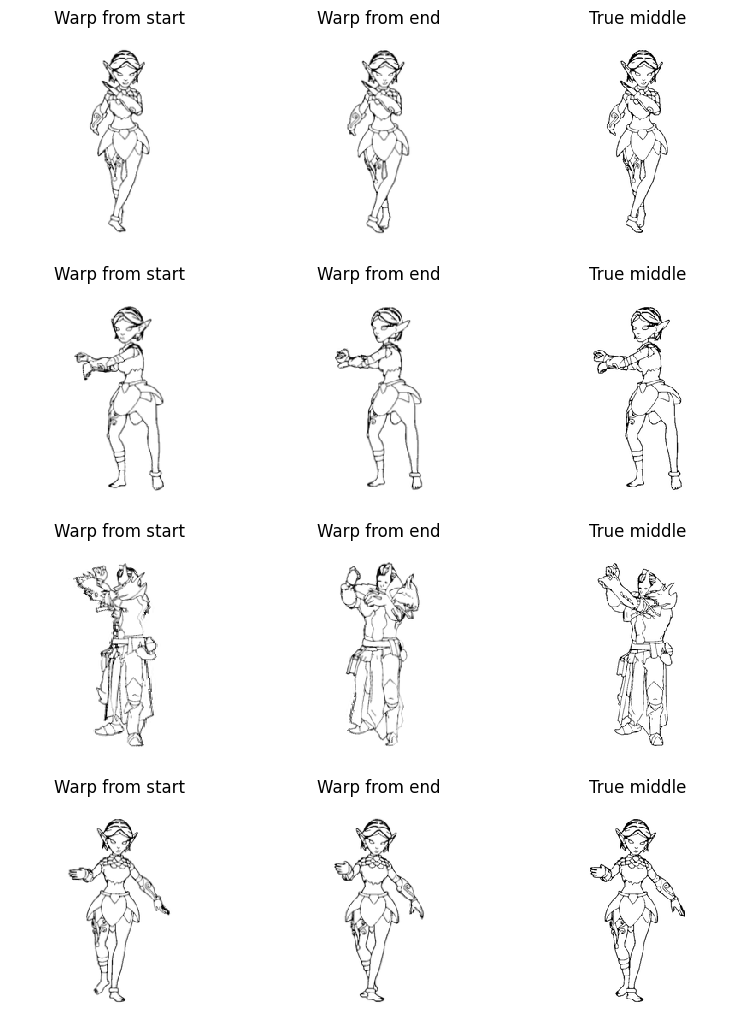

In [29]:
def preview_rows(run, count):
    rng = np.random.default_rng(run.seed)
    groups = defaultdict(list)
    for row in run.splits["val"]:
        groups[int(row["gap"])].append(row)
    for group in groups.values():
        rng.shuffle(group)
    picked = []
    while len(picked) < count and any(groups.values()):
        for gap in sorted(groups):
            if groups[gap] and len(picked) < count:
                picked.append(groups[gap].pop())
    return picked


def warp_check(run):
    chosen = preview_rows(run, PREVIEW_CASES)
    if not chosen:
        return
    fig, axes = plt.subplots(
        len(chosen), 3, squeeze=False, figsize=(8, 2.6 * len(chosen))
    )
    for axrow, row in zip(axes, chosen):
        x, y = run.frames.batch([row])
        a, b, target = x[0, ..., 2], x[0, ..., 3], y[0, ..., 0]
        true_line = target >= run.threshold

        def close_to(warp):
            ink = warp >= run.threshold
            return (
                distance_transform_edt(~ink) <= run.tolerance
                if ink.any()
                else np.zeros_like(ink)
            )

        if true_line.any():
            ca, cb = close_to(a)[true_line], close_to(b)[true_line]
            print(
                f"{row['sequence']} | gap {row['gap']} | true ink near only A {np.mean(ca & ~cb):.0%}, "
                f"only B {np.mean(cb & ~ca):.0%}, both {np.mean(ca & cb):.0%}, neither {np.mean(~ca & ~cb):.0%}"
            )
        for ax, drawing, title in zip(
            axrow, (a, b, target), ("Warp from start", "Warp from end", "True middle")
        ):
            ax.imshow(drawing, cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
            ax.set_title(title)
            ax.axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)


warp_check(run)

## Train and validate through epoch 15

Use all 58,390 training and 29,188 validation examples. Rerunning restores saved progress and skips finished epochs. `EPOCHS` sets the total target.

In [53]:
run = reopen()
try:
    run.train(EPOCHS)
except (KeyboardInterrupt, Exception):
    print(
        "Rerun this cell to restore the latest verified checkpoint. Progress after that checkpoint may repeat.",
        flush=True,
    )
    raise

Using committed local masking checkpoint: (11, 0, 160517)
Device: /job:localhost/replica:0/task:0/device:GPU:0 | policy: mixed_float16 | batch size: 4 | ink weight: 15.0
Completed epoch: 11 | next: 12 | training examples already saved in that epoch: 0

Epoch 12/15: train 14,598 batches; 0/58,390 examples already trained.


Epoch 12/15 train:   0%|          | 0/58390 [00:00<?, ?triplet/s]

Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (54.3 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795112330625643927.zip
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (54.3 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795112459467653611.zip
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (54.3 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795112586981733911.zip
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframe

Full validation:   0%|          | 0/29188 [00:00<?, ?triplet/s]

Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (54.9 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795114107785198294.zip
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (55.5 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795114220067850766.zip
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (56.1 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795114329317403818.zip
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (56.7 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795114438558224822.

Epoch 13/15 train:   0%|          | 0/58390 [00:00<?, ?triplet/s]

... (7 outputs left out)

Epoch 15/15 train:   0%|          | 0/58390 [00:00<?, ?triplet/s]

Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (83.9 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795120282316007487.zip
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (83.9 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795120421013571822.zip
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (83.9 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795120556449491241.zip
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframe

Full validation:   0%|          | 0/29188 [00:00<?, ?triplet/s]

Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (84.5 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795122110583774720.zip
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (85.1 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795122221129119153.zip
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (85.7 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795122329277773577.zip
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (86.3 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/checkpoint_1795122436959443157.

## Compare with the unmasked experiment

Read the saved unmasked report or the recorded comparison values for the same epoch. If matching model weights are available, also show both predictions.

In [54]:
def compare_control(run, epoch, want_model=False):
    report, control_model, origin = None, None, None
    for item in checkpoint_inputs(CONTROL_INPUT):
        try:
            with Bundle(item) as bundle:
                state = bundle.json("training_state.json")
                cfg = state["run_config"]
                if (
                    state.get("experiment") != "epoch10_ink30_to_ink15"
                    or state.get("parent_weights_digest")
                    != run.state["parent_weights_digest"]
                    or any(
                        cfg.get(k) != run.config.get(k)
                        for k in (
                            "data_fingerprint",
                            "feature_version",
                            "positive_weight",
                            "seed",
                            "batch_size",
                            "learning_rate",
                        )
                    )
                ):
                    continue
                entry = next((h for h in state["history"] if h["epoch"] == epoch), None)
                if (
                    not entry
                    or entry.get("compute_policy") != run.compute_policy
                    or not entry.get("report")
                ):
                    continue
                relative = bundle_member(entry["report"]) / "summary.json"
                if not bundle.has(relative):
                    continue
                summary = bundle.json(relative)
                if not (
                    summary["split"] == "val"
                    and summary["data_fingerprint"] == run.meta["fingerprint"]
                    and summary["n_triplets"] == len(run.splits["val"])
                    and summary["threshold"] == run.threshold
                    and summary["tolerance"] == run.tolerance
                    and summary["protocol"] == "raster-line-metrics-v2"
                    and summary["weights_digest"].split("__")[0]
                    == entry["weights_digest"]
                ):
                    continue
                metrics = summary["methods"]["unet"]
                report = dict(
                    loss=summary["val_loss"],
                    ink_ratio=summary["ink_ratio"],
                    ink_mae=summary["val_ink_mae"],
                    line_f1=metrics["line_f1"],
                    chamfer_px=metrics["chamfer_px"],
                )
                origin = f"saved notebook 03 report in {item.name}"
                if want_model:
                    member = None
                    if state["completed_epochs"] == epoch and not state.get("partial"):
                        member = "last.keras"
                    elif (
                        state.get("best_epoch") == epoch
                        and state.get("best_weights_digest") == entry["weights_digest"]
                    ):
                        member = "best.keras"
                    if member and bundle.has(member):
                        dest = TEMP_ROOT / f"interframes_control_epoch_{epoch}.keras"
                        bundle.copy(member, dest)
                        possible = load_network(dest, training=False)
                        if weights_digest(possible) != entry["weights_digest"]:
                            raise ValueError(
                                "Control model does not match its recorded validation weights."
                            )
                        control_model = possible
                if not want_model or control_model is not None:
                    break
        except (KeyError, ValueError, OSError, zipfile.BadZipFile) as error:
            print("Could not use optional control:", item.name, error)
    # Full-validation rows supplied for this exact epoch-10 parent and GPU protocol.
    known = {
        11: (
            0.6262059614978188,
            4.3089324442494945,
            0.07048745280784785,
            0.8240702267684121,
            1.0728352206951781,
        ),
        12: (
            0.6264154925723917,
            4.205418000823337,
            0.06926269836146147,
            0.8268706848747082,
            1.0704278780239498,
        ),
    }
    if (
        report is None
        and epoch in known
        and run.environment == "kaggle_gpu"
        and run.meta["fingerprint"]
        == "0a6873b0e80d50f4180bb7bf454d65ee18cb5539436130324cb261f9468e097c"
        and run.state["parent_weights_digest"]
        == "9aecd613d96ecdcc481cc06f7f527da28fcdcada73ae189f77193faed5bc8539"
        and run.compute_policy == "mixed_float16"
        and run.batch_size == 4
        and run.seed == 42
        and np.isclose(run.config["learning_rate"], 2e-4)
        and len(run.splits["val"]) == 29188
        and run.threshold == 0.5
        and run.tolerance == 2
    ):
        report = dict(
            zip(("loss", "ink_ratio", "ink_mae", "line_f1", "chamfer_px"), known[epoch])
        )
        origin = "your previously reported validation CSV (historical control)"
    return report, control_model, origin


def compare_epoch(run):
    epoch = run.state["completed_epochs"]
    if epoch < 11 or run.state.get("partial"):
        print(
            "The comparison becomes available after a masked epoch finishes validation."
        )
        return None
    entry = next(h for h in run.state["history"] if h["epoch"] == epoch)
    summary = read_json(run.out / entry["report"] / "summary.json")
    control, preview_model, source = compare_control(
        run, epoch, want_model=PREVIEW_CASES > 0
    )
    keys = (
        "loss",
        "ink_ratio",
        "ink_mae",
        "line_f1",
        "chamfer_px",
        "precision",
        "recall",
    )
    rows = []
    if control is not None:
        rows.append(
            dict(
                model="unmasked",
                epoch=epoch,
                source=source,
                **{k: control.get(k) for k in keys},
            )
        )
    else:
        print(
            f"No matching unmasked epoch-{epoch} report. Only measured masked scores will be shown."
        )
    rows.append(
        dict(
            model="masked",
            epoch=epoch,
            source="this run",
            **{k: summary[k] for k in keys},
        )
    )
    if control is not None:
        rows.append(
            dict(
                model="masked minus unmasked",
                epoch=epoch,
                source="paired epoch",
                **{
                    k: summary[k] - control[k]
                    if summary.get(k) is not None and control.get(k) is not None
                    else None
                    for k in keys
                },
            )
        )
    for row in rows:
        row["triplets"] = summary["protocol"]["n_triplets"]
    path = run.out / "evaluation" / f"comparison_epoch_{epoch:03d}.csv"
    with path.with_suffix(".csv.part").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    path.with_suffix(".csv.part").replace(path)
    print(
        f"Epoch {epoch} | {len(run.splits['val']):,} validation triplets | cutoff {run.threshold:g}, tolerance {run.tolerance} px"
    )
    from html import escape
    from IPython.display import HTML

    columns = ("model", *keys)

    def format_value(value):
        if value is None:
            return "—"
        return (
            f"{value:.5f}"
            if isinstance(value, (float, np.floating))
            else escape(str(value))
        )

    header = "".join(f"<th>{key}</th>" for key in columns)
    body = "".join(
        "<tr>"
        + "".join(f"<td>{format_value(row.get(key))}</td>" for key in columns)
        + "</tr>"
        for row in rows
    )
    display(
        HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>")
    )
    if source:
        print("Unmasked metrics from", source)
    print(
        "Higher F1/precision/recall, lower Chamfer, and ink ratio closer to 1 are better."
    )
    print("A blank cell means that metric was absent from the saved control report.")
    share = RESULTS_DIR / f"epoch_{epoch:03d}"
    atomic_copy(path, share / path.name)
    atomic_copy(
        run.out / entry["report"] / "summary.json", share / "masked_summary.json"
    )
    return preview_model


control_preview_model = compare_epoch(run)

No matching unmasked epoch-15 report. Only measured masked scores will be shown.
Epoch 15 | 29,188 validation triplets | cutoff 0.5, tolerance 2 px


model,loss,ink_ratio,ink_mae,line_f1,chamfer_px,precision,recall
masked,0.62117,4.62970,0.07610,0.81847,1.08057,0.72850,0.96034


Higher F1/precision/recall, lower Chamfer, and ink ratio closer to 1 are better.
A blank cell means that metric was absent from the saved control report.


## Compare saved epochs and animations

Combine scores from the original model, the unmasked ink-weight-15 experiment, and the masked experiment. Save each row’s source, plot the comparisons, and preview the available epoch-11 through epoch-15 checkpoints.

In [55]:
def compare_all_epochs(run):
    from html import escape
    from IPython.display import HTML

    columns = (
        "run",
        "epoch",
        "ink_weight",
        "val_loss",
        "ink_mae",
        "line_f1",
        "chamfer_px",
        "ink_ratio",
        "source",
    )
    records = {}

    def history_row(label, weight, entry):
        epoch = int(entry["epoch"])
        row = dict(
            run=label,
            epoch=epoch,
            ink_weight=weight,
            val_loss=entry.get("val_loss"),
            ink_mae=entry.get("val_ink_mae"),
            line_f1=entry.get("val_line_f1"),
            chamfer_px=entry.get("val_chamfer_px"),
            ink_ratio=entry.get("val_ink_ratio"),
            source="saved history",
        )
        records[label, epoch] = row
        return row

    history = run.state["history"]
    parent_history = [h for h in history if h["epoch"] <= 10]
    for entry in parent_history:
        history_row("Original", 30, entry)
    for item in checkpoint_inputs(PARENT_INPUT):
        with Bundle(item) as bundle:
            state = bundle.json("training_state.json")
            if (
                state.get("history") != parent_history
                or state["run_config"].get("data_fingerprint")
                != run.meta["fingerprint"]
                or state["run_config"].get("positive_weight") != 30
                or not bundle.has("evaluation/validation_comparison.csv")
            ):
                continue
            with bundle.open("evaluation/validation_comparison.csv") as f:
                for score in csv.DictReader(line.decode("utf-8-sig") for line in f):
                    row = records.get(("Original", int(score["epoch"])))
                    if row is None or int(score["triplets"]) != len(run.splits["val"]):
                        continue
                    for name, field in (
                        ("val_loss", "loss"),
                        ("ink_mae", "ink_mae"),
                        ("line_f1", "line_f1"),
                        ("chamfer_px", "chamfer_px"),
                        ("ink_ratio", "ink_ratio"),
                    ):
                        if score.get(field):
                            row[name] = float(score[field])
                    row["source"] = "original validation CSV"
            break
    # Epoch-10 ink ratio supplied in the user's weight-15 comparison CSV.
    original = records.get(("Original", 10))
    if (
        original
        and original["ink_ratio"] is None
        and run.state["parent_weights_digest"]
        == "9aecd613d96ecdcc481cc06f7f527da28fcdcada73ae189f77193faed5bc8539"
        and run.meta["fingerprint"]
        == "0a6873b0e80d50f4180bb7bf454d65ee18cb5539436130324cb261f9468e097c"
        and run.threshold == 0.5
        and run.tolerance == 2
        and len(run.splits["val"]) == 29188
    ):
        original["ink_ratio"] = 5.4561923583154215
        original["source"] += " + reported ink ratio"

    control_epochs = {11, 12}
    for item in checkpoint_inputs(CONTROL_INPUT):
        try:
            with Bundle(item) as bundle:
                state = bundle.json("training_state.json")
                if (
                    state.get("experiment") != "epoch10_ink30_to_ink15"
                    or state.get("parent_weights_digest")
                    != run.state["parent_weights_digest"]
                    or any(
                        state["run_config"].get(k) != run.config.get(k)
                        for k in (
                            "data_fingerprint",
                            "feature_version",
                            "positive_weight",
                            "seed",
                            "batch_size",
                            "learning_rate",
                        )
                    )
                ):
                    continue
                for entry in state["history"]:
                    epoch = int(entry["epoch"])
                    if (
                        10 < epoch <= state["completed_epochs"]
                        and entry.get("compute_policy") == run.compute_policy
                    ):
                        control_epochs.add(epoch)
                        if ("Unmasked ink-15", epoch) not in records:
                            history_row("Unmasked ink-15", 15, entry)
        except (OSError, KeyError, ValueError, zipfile.BadZipFile) as err:
            print("Skipping optional control history:", item.name, err)

    for epoch in sorted(control_epochs):
        report, _, origin = compare_control(run, epoch, want_model=False)
        if report is not None:
            row = history_row("Unmasked ink-15", 15, {"epoch": epoch})
            row.update(
                val_loss=report["loss"],
                **{
                    k: report[k]
                    for k in ("ink_mae", "line_f1", "chamfer_px", "ink_ratio")
                },
            )
            row["source"] = origin

    for entry in history:
        if entry["epoch"] > 10:
            history_row("Masked ink-15", 15, entry)

    order = {"Original": 0, "Unmasked ink-15": 1, "Masked ink-15": 2}
    rows = sorted(records.values(), key=lambda r: (r["epoch"], order[r["run"]]))
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    dest = RESULTS_DIR / "all_epochs_comparison.csv"
    temp = dest.with_suffix(".csv.part")
    with temp.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)
    temp.replace(dest)

    def show(v):
        if v is None:
            return "—"
        return f"{v:.5f}" if isinstance(v, float) else escape(str(v))

    header = "".join(f"<th>{k}</th>" for k in columns[:-1])
    body = "".join(
        "<tr>" + "".join(f"<td>{show(r[k])}</td>" for k in columns[:-1]) + "</tr>"
        for r in rows
    )
    display(
        HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>")
    )
    print(
        "Blank metrics were unavailable. Compare loss within the same ink weight. Saved:",
        dest,
    )


compare_all_epochs(run)

run,epoch,ink_weight,val_loss,ink_mae,line_f1,chamfer_px,ink_ratio
Original,1,30,0.73779,0.10474,—,—,—
Original,2,30,0.74086,0.12055,—,—,—
Original,3,30,0.72940,0.10002,—,—,—
Original,4,30,0.73069,0.09541,—,—,—
Original,5,30,0.72468,0.10045,—,—,—
Original,6,30,0.72569,0.09919,—,—,—
Original,7,30,0.72352,0.09931,0.79191,1.11957,—
Original,8,30,0.72456,0.09964,—,—,—
Original,9,30,0.72852,0.09552,—,—,—
Original,10,30,0.73066,0.09168,0.80215,1.08600,5.45619


Blank metrics were unavailable. Compare loss within the same ink weight. Saved: /kaggle/working/interframes_tf_stage4_masking/results/all_epochs_comparison.csv


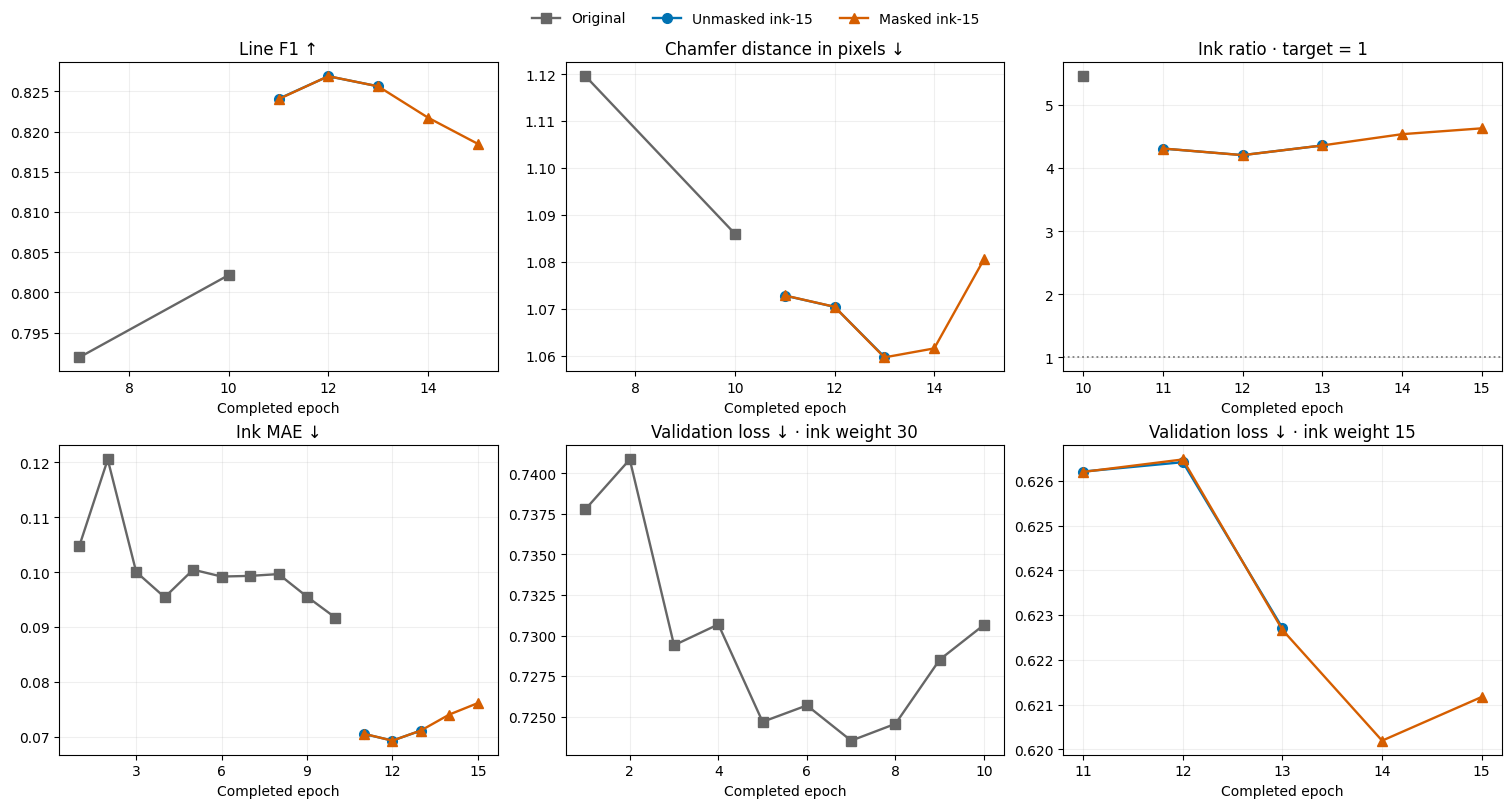

Saved: /kaggle/working/interframes_tf_stage4_masking/results/all_epochs_metrics.png


In [56]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

scores = pd.read_csv(RESULTS_DIR / "all_epochs_comparison.csv")

styles = {
    "Original": {"color": "0.40", "marker": "s"},
    "Unmasked ink-15": {"color": "#0072B2", "marker": "o"},
    "Masked ink-15": {"color": "#D55E00", "marker": "^"},
}

# Separate loss panels because the original run used a different ink weight.
panels = [
    ("line_f1", "Line F1 ↑", list(styles)),
    ("chamfer_px", "Chamfer distance in pixels ↓", list(styles)),
    ("ink_ratio", "Ink ratio · target = 1", list(styles)),
    ("ink_mae", "Ink MAE ↓", list(styles)),
    ("val_loss", "Validation loss ↓ · ink weight 30", ["Original"]),
    (
        "val_loss",
        "Validation loss ↓ · ink weight 15",
        ["Unmasked ink-15", "Masked ink-15"],
    ),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
legend_handles = {}

for ax, (metric, title, runs) in zip(axes.flat, panels):
    for name in runs:
        points = (
            scores.loc[scores["run"].eq(name), ["epoch", metric]]
            .dropna()
            .sort_values("epoch")
        )
        if points.empty:
            continue

        (line,) = ax.plot(
            points["epoch"],
            points[metric],
            label=name,
            linewidth=1.7,
            markersize=7,
            **styles[name],
        )
        legend_handles[name] = line

    if metric == "ink_ratio":
        ax.axhline(1, color="0.5", linestyle=":", linewidth=1.3)

    ax.set_title(title)
    ax.set_xlabel("Completed epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
    ax.grid(alpha=0.2)

fig.legend(
    [legend_handles[name] for name in styles if name in legend_handles],
    [name for name in styles if name in legend_handles],
    loc="outside upper center",
    ncol=3,
    frameon=False,
)

path = RESULTS_DIR / "all_epochs_metrics.png"
fig.savefig(path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", path)

In [89]:
import json
import random
import numpy as np
from functools import lru_cache
from PIL import Image as PILImage, ImageDraw
from IPython.display import Image as NotebookImage, display
import evaluation
import learning
import raft_tf


@lru_cache(maxsize=4)
def animation_cases(root, split, three_frames):
    if three_frames:
        return evaluation.recursive_cases(root, split)
    return [(r, None, None) for r in raster.read_records(root) if r["split"] == split]


@lru_cache(maxsize=1)
def animation_raft(root):
    config = json.loads((root / "config.json").read_text())
    return raft_tf.RAFTSmallTF(
        root / "raft_small_tf.npz",
        iterations=int(config.get("raft_iterations", 12)),
    )


def show_animation(
    checkpoint="last",
    split="val",
    gap=4,
    seed=42,
    inbetweens=3,
    fps=4,
    ink_cutoff=None,
    compare_unmasked=False,
    sequence=None,
    ping_pong=True,
    ink_color="black",
):
    if checkpoint not in ("last", "best") or inbetweens not in (1, 3):
        raise ValueError("Choose checkpoint='last' or 'best', and inbetweens=1 or 3.")
    if fps <= 0 or (ink_cutoff is not None and not 0 <= ink_cutoff <= 1):
        raise ValueError("Use positive fps and an ink_cutoff from 0 to 1, or None.")
    if run.state.get("partial"):
        raise ValueError("Finish the current epoch before comparing saved checkpoints.")

    epoch = run.state["completed_epochs" if checkpoint == "last" else "best_epoch"]
    if epoch < 11:
        raise ValueError("Run this after the first masked epoch has finished.")

    cases = animation_cases(run.root, split, inbetweens == 3)
    candidates = [
        case
        for case in cases
        if case[0]["gap"] == gap
        and (sequence is None or sequence.lower() in case[0]["sequence"].lower())
    ]
    if not candidates:
        raise ValueError(
            "No matching drawing. Try gap=2 or 4, or change the sequence filter."
        )
    row, quarter_path, three_quarter_path = random.Random(seed).choice(candidates)

    masked = (
        run.model
        if checkpoint == "last"
        else load_network(run.best_path, training=False)
    )
    models = [(f"Masked {checkpoint} | epoch {epoch}", masked)]
    if compare_unmasked:
        _, control, _ = compare_control(run, epoch, want_model=True)
        if control is None:
            print(
                f"No unmasked epoch-{epoch} weights found in CONTROL_INPUT. Showing masked + truth."
            )
        else:
            models.append((f"Unmasked | epoch {epoch}", control))

    # Build the cached midpoint input once so both models see identical motion.
    flows = run.frames.flows.get(split)
    if flows is None:
        flows = raster.open_flows(run.root, split)
    x = raster.row_features(run.root, row, flows)[None]
    start = run.frames.ink(row["a"])
    end = run.frames.ink(row["b"])
    paths = [row["a"], row["target"], row["b"]]
    if inbetweens == 3:
        paths = [row["a"], quarter_path, row["target"], three_quarter_path, row["b"]]

    columns = []
    for label, model in models:
        mid = tf.sigmoid(model(x, training=False))[0, ..., 0].numpy()
        drawings = [start, mid, end]
        if inbetweens == 3:
            motion = animation_raft(run.root)
            q1 = learning.predict_middle(model, motion, start, mid)
            q3 = learning.predict_middle(model, motion, mid, end)
            drawings = [start, q1, mid, q3, end]

        # Apply the cutoff only for display, after all predictions are complete.
        if ink_cutoff is not None:
            drawings = (
                [start]
                + [(p >= ink_cutoff).astype("float32") for p in drawings[1:-1]]
                + [end]
            )
        columns.append((label, drawings))

    columns.append(("Ground truth", [run.frames.ink(p) for p in paths]))
    height, width = start.shape
    frames = []
    for i in range(len(paths)):
        canvas = PILImage.new("RGB", ((width + 4) * len(columns), height + 30), "white")
        pen = ImageDraw.Draw(canvas)
        percent = round(100 * i / (len(paths) - 1))
        for j, (label, drawings) in enumerate(columns):
            left = j * (width + 4)
            pen.text((left + 4, 7), f"{label} | {percent}%", fill="black")
            from PIL import ImageOps

            gray = raster.ink_image(drawings[i])
            color = "black" if label == "Ground truth" else ink_color
            colored = ImageOps.colorize(gray, black=color, white="white")
            canvas.paste(colored, (left, 30))

        frames.append(canvas)

    playback = frames + frames[-2:0:-1] if ping_pong else frames
    folder = RESULTS_DIR / "animations"
    folder.mkdir(parents=True, exist_ok=True)
    cutoff_tag = "raw" if ink_cutoff is None else f"cut{ink_cutoff:g}"
    path = folder / (
        f"{split}_{row['id']}_{checkpoint}_ep{epoch}_{inbetweens}mid_"
        f"{cutoff_tag}_{len(models)}model_{fps}fps_{'bounce' if ping_pong else 'forward'}.gif"
    )
    playback[0].save(
        path,
        save_all=True,
        append_images=playback[1:],
        duration=max(10, round(1000 / fps)),
        loop=0,
    )
    print(f"{row['sequence']} | gap {gap} | seed {seed} | {path.name}")
    display(NotebookImage(data=path.read_bytes(), format="gif"))
    print("Saved:", path)


Masked epoch 11
standing_2h_magic_attack_05_warrok | gap 4 | seed 33 | val_15f52f60910b4800ed04_last_ep11_3mid_cut0.8_1model_3fps_bounce.gif


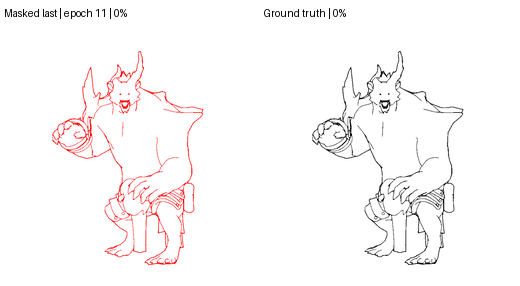

Saved: /kaggle/working/interframes_tf_stage4_masking/results/animations/val_15f52f60910b4800ed04_last_ep11_3mid_cut0.8_1model_3fps_bounce.gif
Masked epoch 12
standing_2h_magic_attack_05_warrok | gap 4 | seed 33 | val_15f52f60910b4800ed04_last_ep12_3mid_cut0.8_1model_3fps_bounce.gif


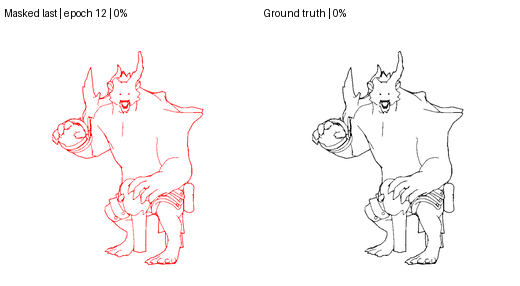

Saved: /kaggle/working/interframes_tf_stage4_masking/results/animations/val_15f52f60910b4800ed04_last_ep12_3mid_cut0.8_1model_3fps_bounce.gif
Masked epoch 13
standing_2h_magic_attack_05_warrok | gap 4 | seed 33 | val_15f52f60910b4800ed04_last_ep13_3mid_cut0.8_1model_3fps_bounce.gif


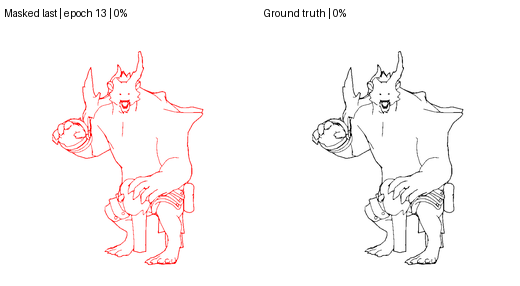

Saved: /kaggle/working/interframes_tf_stage4_masking/results/animations/val_15f52f60910b4800ed04_last_ep13_3mid_cut0.8_1model_3fps_bounce.gif
Masked epoch 14
standing_2h_magic_attack_05_warrok | gap 4 | seed 33 | val_15f52f60910b4800ed04_last_ep14_3mid_cut0.8_1model_3fps_bounce.gif


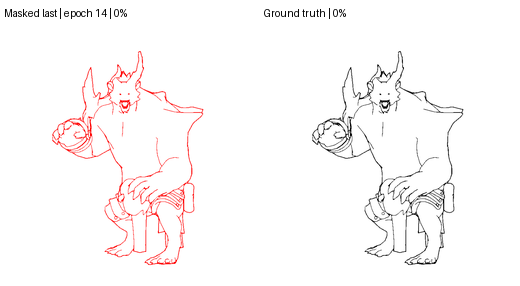

Saved: /kaggle/working/interframes_tf_stage4_masking/results/animations/val_15f52f60910b4800ed04_last_ep14_3mid_cut0.8_1model_3fps_bounce.gif
Masked epoch 15
standing_2h_magic_attack_05_warrok | gap 4 | seed 33 | val_15f52f60910b4800ed04_last_ep15_3mid_cut0.8_1model_3fps_bounce.gif


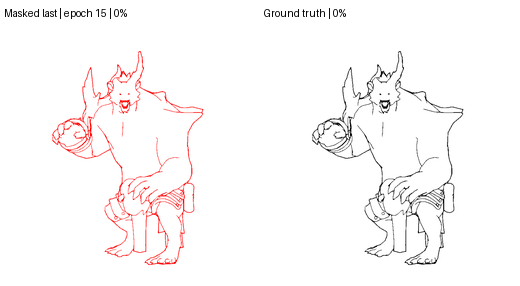

Saved: /kaggle/working/interframes_tf_stage4_masking/results/animations/val_15f52f60910b4800ed04_last_ep15_3mid_cut0.8_1model_3fps_bounce.gif


In [95]:
from pathlib import Path
from tempfile import TemporaryDirectory
import shutil
import zipfile

checkpoint_dir = Path("/kaggle/working/masking_checkpoints")
epochs_to_preview = [
    11,
    12,
    13,
    14,
    15,
]  # Add 12 here to compare the lower-ink checkpoint too.

original_model = run.model
original_state = run.state

try:
    for epoch in epochs_to_preview:
        archive = checkpoint_dir / f"epoch_{epoch:03d}.zip"
        if not archive.is_file():
            raise FileNotFoundError(
                f"Missing {archive}. Check which epoch ZIPs are available."
            )

        with TemporaryDirectory() as temp, zipfile.ZipFile(archive) as z:
            member = marker_in_zip(z, "training_state.json")
            state = json.loads(z.read(member))
            if state["completed_epochs"] != epoch or state.get("partial"):
                raise ValueError(
                    f"{archive.name} does not contain a completed epoch {epoch}."
                )

            model_member = (Path(member).parent / "last.keras").as_posix()
            model_path = Path(temp) / "last.keras"
            with z.open(model_member) as src, model_path.open("wb") as dst:
                shutil.copyfileobj(src, dst)

            run.model = load_network(model_path, training=False)
            run.state = state
            print(f"Masked epoch {epoch}")
            show_animation(
                checkpoint="last",
                split="val",
                gap=4,
                seed=33,  # Same seed gives both models the same drawing.
                inbetweens=3,  # Inspect the directly predicted midpoint.
                fps=3,
                ink_cutoff=0.8,  # Raw ink. Use 0.50 to see the evaluation cutoff.
                compare_unmasked=False,
                ink_color="red",
            )
finally:
    run.model = original_model
    run.state = original_state

## Inspect masks and export checkpoints

Show both rough drawings, their learned masks, the prediction, and the true middle. If the unmasked comparison weights are missing, the reference panel uses the trained U-Net with its masks bypassed. Export the saved masking checkpoints in the final cell.

Comparison preview: Same weights, gates bypassed | masks: dark purple = suppress, yellow = keep.


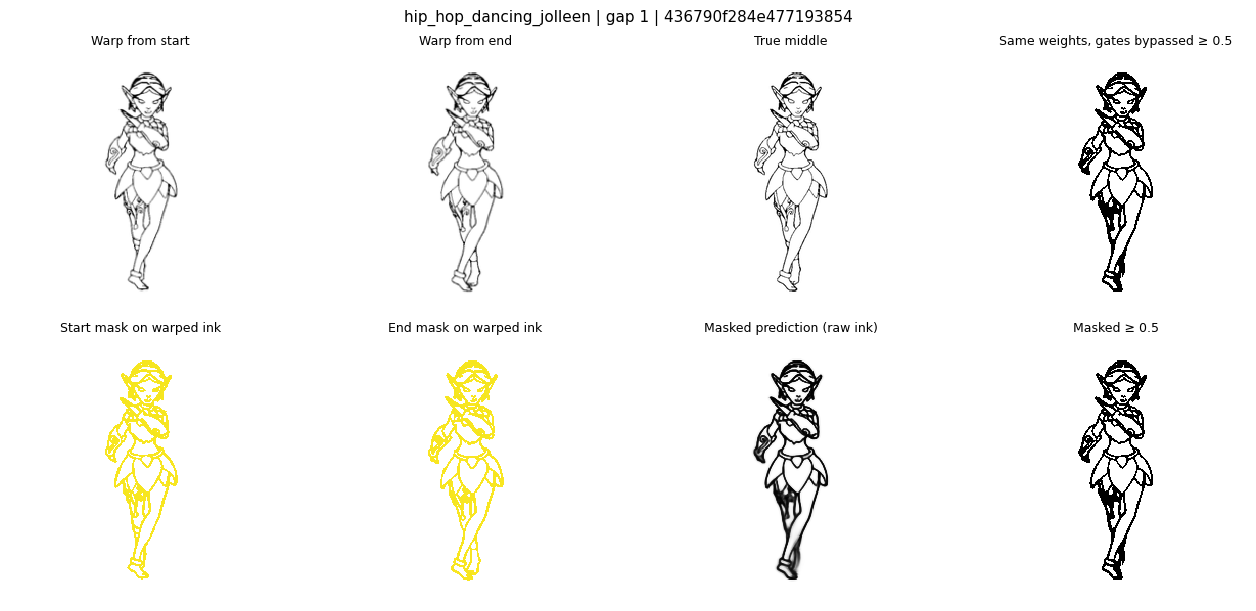

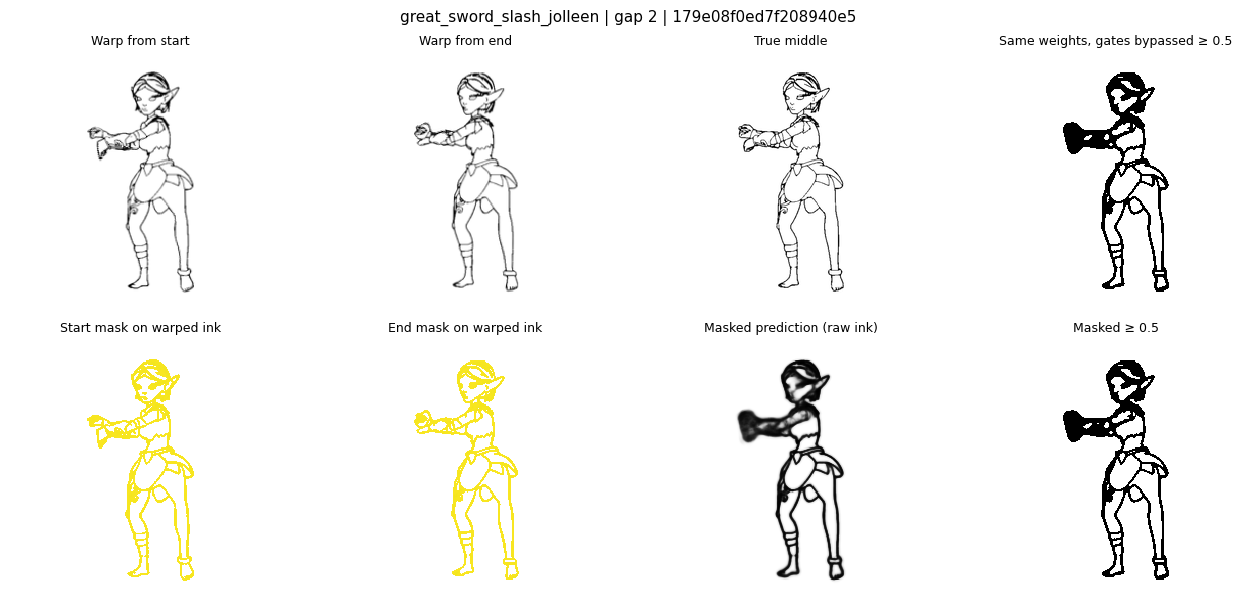

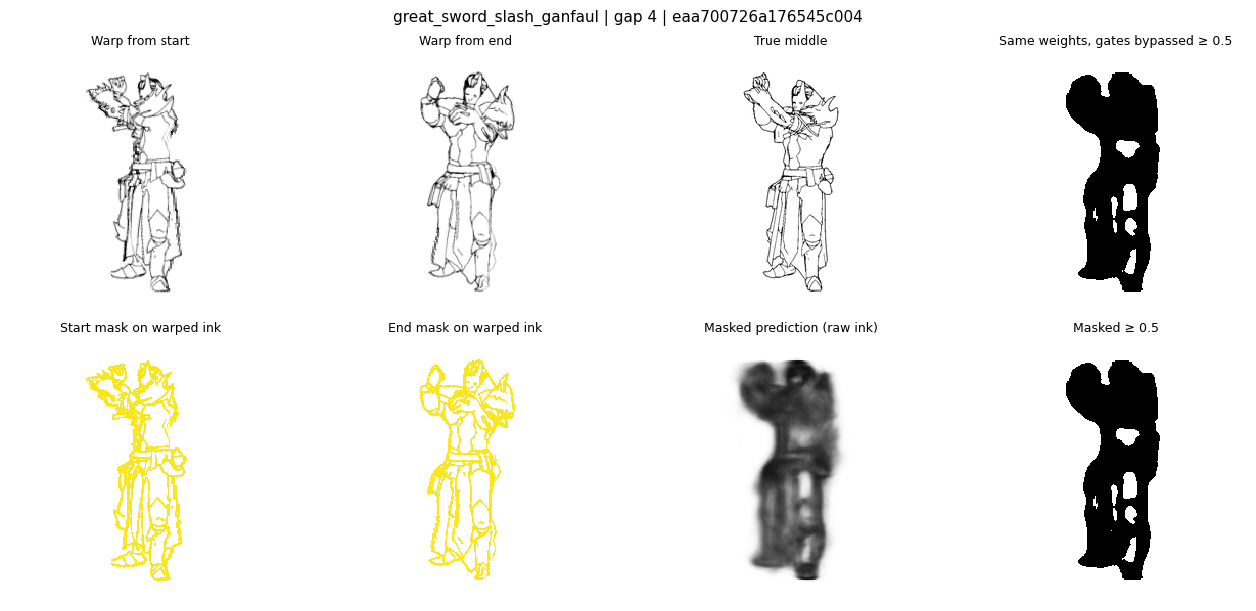

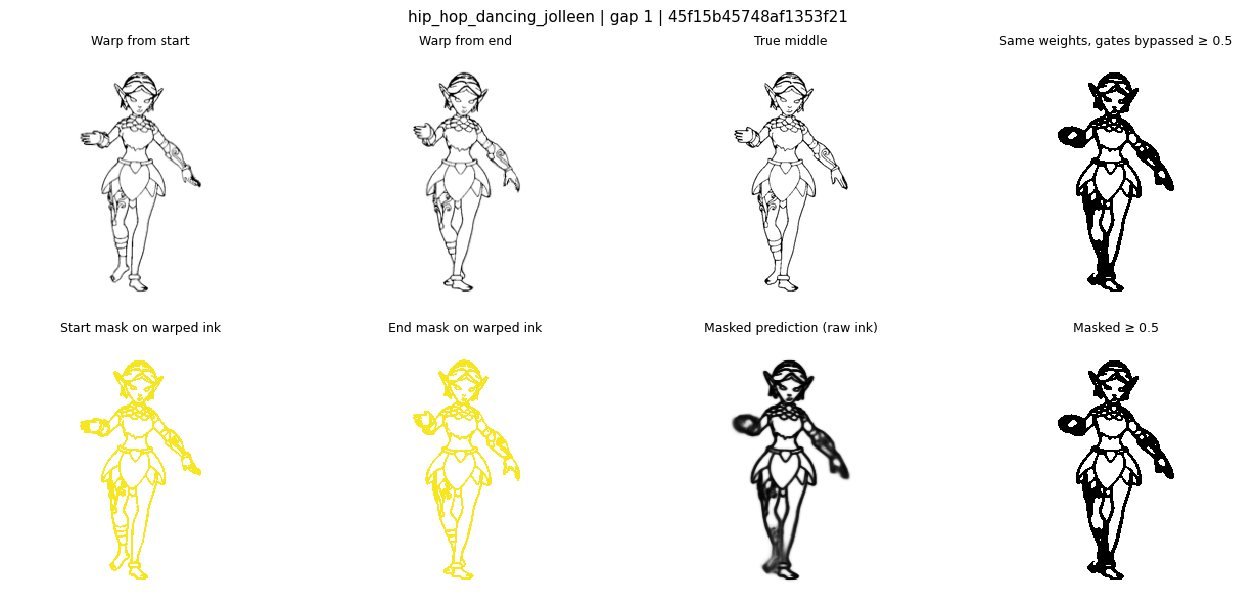

Same-drawing preview scores and PNGs saved to /kaggle/working/interframes_tf_stage4_masking/results/epoch_015
Creating disk backup ZIP...
Backup verified: /kaggle/working/interframes_stage4_masking_backup.zip (100.1 MiB)
Saving a checkpoint under /kaggle/working...
Checkpoint ZIP verified: /kaggle/working/masking_checkpoints/epoch_015.zip
Verified session backups: /kaggle/working/masking_checkpoints
Metric tables and previews: /kaggle/working/interframes_tf_stage4_masking/results
Download this portable ZIP or retain it in saved notebook outputs: /kaggle/working/interframes_stage4_masking_backup.zip


/kaggle/working/interframes_stage4_masking_backup.zip

In [96]:
def mask_panels(run, control):
    rows = preview_rows(run, PREVIEW_CASES)
    epoch = run.state["completed_epochs"]
    if epoch < 11 or run.state.get("partial") or not rows:
        return
    outputs = keras.Model(
        run.model.input,
        [run.model.output, run.model.get_layer("warp_visibility").output],
    )
    bypass = run.model.get_layer("interframes_unet")
    reference = control if control is not None else bypass
    ref_name = (
        f"Unmasked epoch {epoch}"
        if control is not None
        else "Same weights, gates bypassed"
    )
    print(
        "Comparison preview:",
        ref_name,
        "| masks: dark purple = suppress, yellow = keep.",
    )
    folder = run.out / "previews" / f"epoch_{epoch:03d}"
    share = RESULTS_DIR / folder.name
    folder.mkdir(parents=True, exist_ok=True)
    example_scores = []
    for index, row in enumerate(rows, 1):
        x, y = run.frames.batch([row])
        logits, gates = outputs(x, training=False)
        pred = tf.sigmoid(logits).numpy()[0, ..., 0]
        other = tf.sigmoid(reference(x, training=False)).numpy()[0, ..., 0]
        gate = gates.numpy()[0]
        target = y[0, ..., 0]
        wa, wb = x[0, ..., 2], x[0, ..., 3]
        fig, axes = plt.subplots(2, 4, figsize=(13, 6), constrained_layout=True)
        views = [
            (wa, "Warp from start"),
            (wb, "Warp from end"),
            (target, "True middle"),
            (other >= run.threshold, f"{ref_name} ≥ {run.threshold:g}"),
            (np.ma.masked_where(wa < 0.10, gate[..., 0]), "Start mask on warped ink"),
            (np.ma.masked_where(wb < 0.10, gate[..., 1]), "End mask on warped ink"),
            (pred, "Masked prediction (raw ink)"),
            (pred >= run.threshold, f"Masked ≥ {run.threshold:g}"),
        ]
        for j, (ax, (drawing, title)) in enumerate(zip(axes.flat, views)):
            ax.imshow(
                drawing,
                cmap="viridis" if j in (4, 5) else "gray_r",
                vmin=0,
                vmax=1,
                interpolation="nearest",
            )
            ax.set_title(title, fontsize=9)
            ax.axis("off")
        fig.suptitle(f"{row['sequence']} | gap {row['gap']} | {row['id']}", fontsize=11)
        path = folder / f"case_{index:02d}.png"
        fig.savefig(path, dpi=140)
        plt.show()
        plt.close(fig)
        atomic_copy(path, share / path.name)
        for name, drawing in ((ref_name, other), ("Masked", pred)):
            scores = score_lines(drawing, target, run.threshold, run.tolerance)
            example_scores.append(
                dict(
                    id=row["id"],
                    gap=row["gap"],
                    model=name,
                    **dict(zip(QUALITY, scores)),
                )
            )
    path = folder / "preview_scores.csv"
    with path.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(example_scores[0]))
        writer.writeheader()
        writer.writerows(example_scores)
    atomic_copy(path, share / path.name)
    print("Same-drawing preview scores and PNGs saved to", share)


mask_panels(run, control_preview_model)
run.backup()
print("Verified session backups:", CHECKPOINT_DIR)
print("Metric tables and previews:", RESULTS_DIR)
print("Download this portable ZIP or retain it in saved notebook outputs:", BACKUP_ZIP)
from IPython.display import FileLink

display(FileLink(os.path.relpath(BACKUP_ZIP, Path.cwd())))


In [97]:
from pathlib import Path
from zipfile import ZipFile, ZIP_STORED
from IPython.display import FileLink, display
import os

folder = Path("/kaggle/working/masking_checkpoints")
output = folder.parent / "masking_checkpoints_all.zip"
files = sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix != ".part")

if not files:
    raise FileNotFoundError(f"No checkpoint files found in {folder}")

# The checkpoints are already ZIPs, so package them without recompressing.
temp = output.with_suffix(".zip.part")
with ZipFile(temp, "w", compression=ZIP_STORED, allowZip64=True) as archive:
    for path in files:
        archive.write(path, path.relative_to(folder.parent))
temp.replace(output)

print(f"Packed {len(files)} files · {output.stat().st_size / 1024**2:.1f} MiB")
print("Epoch ZIPs:", ", ".join(p.name for p in files if p.name.startswith("epoch_")))
display(
    FileLink(os.path.relpath(output), result_html_prefix="Download all checkpoints: ")
)

Packed 8 files · 550.3 MiB
Epoch ZIPs: epoch_011.zip, epoch_012.zip, epoch_013.zip, epoch_014.zip, epoch_015.zip


/kaggle/working/masking_checkpoints_all.zip